# 02 EDA（探索的データ分析）

`01_data_fetch` が作った `data/processed/observations.parquet`（1 行 ＝ 都市 × 正時）を見て、
雲底高度（シーリング）の予測で **目的変数をどう扱うか** を決める材料を集める。決定と根拠の要約は `docs/eda.md`。

- 決めること：D1 シーリングなしの扱い／D2 高さのない BKN・OVC の層の扱い／D3 `VV`（鉛直視程）の扱い／
  D4 METAR が付かなかった正時の扱い／D5 分割（学習 2018〜2023・検証 2024・テスト 2025）。
- **欠損と件数（1・8 節）は全期間、目的変数の分布や特徴量との関係（2〜7 節）は学習期間（2018〜2023）だけ** で見る
  （検証・テストの年の中身を見て扱いを決めない）。
- 区分けなどの集計の中身は `ml/eda.py` にある（テスト済み）。このノートブックは表と図を出すだけ。
- 既定は **サンプル**（`tests/fixtures/data_raw/` の 2 日ぶん。動くことの確認用で、数値に意味はない）。
  コミットしてある出力は、環境変数 `DATA_FETCH_MODE=full` を付けて全期間で実行したもの。外部とは通信しない。
- 時刻は UTC。季節と時刻（時）だけ現地時間。単位は摂氏・メートル。図の中の文字は英語。

出典：Weather data by Open-Meteo.com（CC BY 4.0）、Iowa Environmental Mesonet（Iowa State University）。

**出力の作り直し方**（`Dockerfile.dev` のイメージの中で。1 行目が全期間での実行と書き戻し、2 行目が実行時刻の削除）。
nbmake はセルごとの実行時刻を書き込むので、消してからコミットする（再実行のたびに差分が出るため。`tests/test_notebooks.py` が確かめている）。

```bash
docker run --rm --network none -e DATA_FETCH_MODE=full -v "${PWD}:/work" cloud-weather-dev uv run --locked pytest --nbmake --overwrite notebooks/02_eda.ipynb
docker run --rm --network none -v "${PWD}:/work" cloud-weather-dev uv run --locked python -c "import json, pathlib; p = pathlib.Path('notebooks/02_eda.ipynb'); nb = json.loads(p.read_text(encoding='utf-8')); [c['metadata'].pop('execution', None) for c in nb['cells']]; p.write_text(json.dumps(nb, ensure_ascii=False, indent=1) + '\n', encoding='utf-8')"
```

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from app.cities import City
from ml import archive, dataset, eda, metar, raw_store

## 0. 設定・読み込み

In [2]:
MODE = os.environ.get("DATA_FETCH_MODE", "sample")
SEED = 0
TRAIN_YEARS = list(range(2018, 2024))
SPLIT = {**dict.fromkeys(TRAIN_YEARS, "train"), 2024: "validation", 2025: "test"}

# 区分・都市の色は、順番を固定して使う（図ごとに変えない）。
STATUS_COLORS = dict(
    zip(
        eda.STATUSES,
        ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"],
        strict=True,
    )
)
CITY_COLORS = {"tokyo": "#2a78d6", "berlin": "#eb6834"}
SURFACE = "#fcfcfb"

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update(
    {
        "figure.dpi": 72,
        "figure.figsize": (10, 3.6),
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)
print(f"mode={MODE}")

mode=full


In [3]:
if MODE == "full":
    observations = dataset.load_dataset(ROOT / "data" / "processed" / "observations.parquet")
elif MODE == "sample":
    raw_root = ROOT / "tests" / "fixtures" / "data_raw"
    parts = {}
    for city in City:
        weather_path = raw_store.raw_path(raw_root, "open_meteo_archive", city, 2025, "json")
        metar_path = raw_store.raw_path(raw_root, "iem", city, 2025, "csv")
        parts[city.value] = (
            archive.parse_archive(weather_path.read_bytes().decode("utf-8")),
            metar.parse_metar(metar_path.read_bytes().decode("utf-8")),
        )
    observations = dataset.build_dataset(parts)
else:
    raise ValueError("DATA_FETCH_MODE must be 'sample' or 'full'")

dataset.validate_dataset(observations)
print(observations.shape, observations["time"].min(), observations["time"].max())

(140256, 28) 2018-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00


`ml/eda.py` の関数で、行ごとの区分などを付ける。

| `status` | 意味 |
|---|---|
| `no_metar` | 前後 30 分以内に METAR がない |
| `no_layers` | METAR はあるが、雲の層の報告がない（電文の `CAVOK` など） |
| `no_ceiling_layer` | 雲の層はあるが、BKN・OVC がない（FEW・SCT・NSC・NCD） |
| `ceiling` | BKN・OVC があり、そのすべてに高さがある |
| `ceiling_skipped_layer` | 高さのない BKN・OVC（`BKN///`）を飛ばして、別の BKN・OVC から `ceiling_m` が決まった |
| `height_unknown` | BKN・OVC はあるが、どれにも高さがない（`ceiling_m` は欠損） |
| `vertical_visibility` | `VV`（鉛直視程）で、BKN・OVC がない（`ceiling_m` は欠損） |

In [4]:
obs = observations.assign(
    year=observations["time"].dt.year,
    status=eda.ceiling_status(observations),
    skipped=eda.skipped_layer_position(observations),
    season=eda.season(observations),
    local_hour=eda.local_hour(observations),
    has_ceiling=observations["ceiling_m"].notna(),
    spread_c=eda.dew_point_spread_c(observations["temperature_c"], observations["dew_point_c"]),
    metar_spread_c=eda.dew_point_spread_c(
        observations["metar_temperature_c"], observations["metar_dew_point_c"]
    ),
)
obs["split"] = obs["year"].map(SPLIT)
# サンプル（2025 年の 2 日ぶん）には学習期間の行がないので、絞らずに全部を使う。
train = obs[obs["split"] == "train"] if MODE == "full" else obs
CITIES = [city.value for city in City if city.value in set(obs["city"])]
STATUS_ORDER = list(eda.STATUSES)
SEASON_ORDER = list(eda.SEASONS)

pd.DataFrame({"all": obs.groupby("city").size(), "train": train.groupby("city").size()})

,all,train
city,,
berlin,70128,52584
tokyo,70128,52584


In [5]:
def status_counts(table: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    """区分ごとの件数（行 = by、列 = status）。"""
    counts = pd.crosstab([table[name] for name in by], table["status"])
    return counts.reindex(columns=STATUS_ORDER, fill_value=0)


def percent(counts: pd.DataFrame) -> pd.DataFrame:
    """行ごとの割合（%）。"""
    return counts.div(counts.sum(axis=1), axis=0) * 100


def plot_status_share(table: pd.DataFrame, by: str, title: str) -> pd.DataFrame:
    """都市ごとに、区分の割合の積み上げ棒を描く。同じ数値の表を返す。"""
    shares = percent(status_counts(table, ["city", by]))
    fig, axes = plt.subplots(1, len(CITIES), figsize=(11, 3.6), sharey=True, squeeze=False)
    for ax, city in zip(axes[0], CITIES, strict=True):
        part = shares.loc[city]
        part.plot.bar(
            stacked=True,
            ax=ax,
            legend=False,
            width=0.85,
            color=[STATUS_COLORS[name] for name in part.columns],
            edgecolor=SURFACE,
            linewidth=1,
        )
        ax.set_title(f"{city}: {title}")
        ax.set_xlabel(by)
        ax.set_ylabel("share of hours (%)")
        ax.grid(axis="x", visible=False)
    axes[0][-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    plt.show()
    return shares


def plot_by_city(table: pd.DataFrame, title: str, ylabel: str) -> pd.DataFrame:
    """行 = 横軸、列 = 都市 の表を、都市ごとの折れ線で描く。同じ表を返す。"""
    fig, ax = plt.subplots()
    for city in table.columns:
        ax.plot(
            [str(value) for value in table.index],
            table[city],
            marker="o",
            color=CITY_COLORS[city],
            label=city,
        )
    ax.set_title(title)
    ax.set_xlabel(table.index.name)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.show()
    return table

## 1. 欠損（全期間）

列ごと・都市ごとの欠損の数。気象（Open-Meteo）の列に欠損がなければ、表には METAR の列だけが出る。

In [6]:
missing = obs[list(observations.columns)].isna().groupby(obs["city"]).sum().T
missing[missing.sum(axis=1) > 0]

city,berlin,tokyo
metar_observed_at,7,6
metar_temperature_c,8,6
metar_dew_point_c,9,6
visibility_m,7,6
sky_cover_1,35321,7091
sky_cover_2,59262,25766
sky_cover_3,67624,53775
sky_cover_4,69780,69801
sky_height_1_m,37524,7264
sky_height_2_m,59810,36727


METAR が付かなかった正時（D4）。

In [7]:
without_metar = obs.loc[obs["metar"].isna(), ["city", "time", "year"]]
display(without_metar.groupby(["city", "year"]).size().unstack(fill_value=0))
without_metar[["city", "time"]]

year,2018,2020,2021,2022,2023
city,,,,,
berlin,2,2,2,1,0
tokyo,1,1,1,0,3


,city,time
7838,berlin,2018-11-23 14:00:00+00:00
7839,berlin,2018-11-23 15:00:00+00:00
19752,berlin,2020-04-03 00:00:00+00:00
19753,berlin,2020-04-03 01:00:00+00:00
28183,berlin,2021-03-20 07:00:00+00:00
32945,berlin,2021-10-04 17:00:00+00:00
36524,berlin,2022-03-02 20:00:00+00:00
77967,tokyo,2018-11-23 15:00:00+00:00
89878,tokyo,2020-04-02 22:00:00+00:00
98311,tokyo,2021-03-20 07:00:00+00:00


付いた METAR の観測時刻と正時の差（分。負は正時より前）。

In [8]:
offset_min = (obs["metar_observed_at"] - obs["time"]).dt.total_seconds().div(60).rename("minutes")
pd.crosstab(offset_min, obs["city"])

city,berlin,tokyo
minutes,,
-30.00,0,10
-10.00,70104,0
0.00,0,70109
20.00,17,0
30.00,0,3


雲の量の列（4 層ぶん）に入っている値。前後の空白が分かるように `[]` で囲む。

In [9]:
covers = pd.concat([obs[f"sky_cover_{layer}"] for layer in metar.LAYERS])
("[" + covers + "]").value_counts(dropna=False).to_frame("layers")

,layers
NaN,388420
[FEW],73051
[BKN],67715
[SCT],22820
[OVC],6774
[NSC],1586
[NCD],429
[VV ],229


`VV`（鉛直視程）の行で、高さが入っているか（D3）。件数は全期間。
高さ・視程の分布は学習期間だけ（検証・テストの年は、件数しか見ない）。

In [10]:
vv = obs[obs["status"] == eda.VERTICAL_VISIBILITY]
vv_height = vv["sky_height_1_m"].notna().map({True: "with_height", False: "without_height"})
display(pd.crosstab([vv["city"], vv["split"], vv["year"]], vv_height))
vv_train = train[train["status"] == eda.VERTICAL_VISIBILITY]
vv_train.groupby("city")[["sky_height_1_m", "visibility_m"]].describe(percentiles=[0.5]).T

sky_height_1_m          with_height  without_height
city   split      year                             
berlin test       2025           81               0
       train      2018            0              29
                  2019            0              14
                  2020            0              10
                  2021            0              15
                  2022           15               0
                  2023           14               0
       validation 2024           50               0
tokyo  train      2020            1               0

city                  berlin  tokyo
sky_height_1_m count   29.00   1.00
               mean    77.78  60.96
               std     15.43    NaN
               min     60.96  60.96
               50%     91.44  60.96
               max     91.44  60.96
visibility_m   count   97.00   1.00
               mean   330.00 804.67
               std    183.05    NaN
               min     48.28 804.67
               50%    305.78 804.67
               max    901.23 804.67

## 2. シーリングの決まり方の内訳（学習期間）

`ceiling_m` が欠損の行は、理由が 5 つある（`no_metar`・`no_layers`・`no_ceiling_layer`・`height_unknown`・`vertical_visibility`）。
「雲が少ない・ない」（D1）と「高さが分からない」（D2）と `VV`（D3）を分けて数える。

In [11]:
counts = status_counts(train, ["city"])
display(counts)
percent(counts)

status,no_metar,no_layers,no_ceiling_layer,ceiling,ceiling_skipped_layer,height_unknown,vertical_visibility
city,,,,,,,
berlin,7,26376,9822,16273,1,8,97
tokyo,6,4540,17184,21136,1258,8459,1


status,no_metar,no_layers,no_ceiling_layer,ceiling,ceiling_skipped_layer,height_unknown,vertical_visibility
city,,,,,,,
berlin,0.01,50.16,18.68,30.95,0.00,0.02,0.18
tokyo,0.01,8.63,32.68,40.19,2.39,16.09,0.00


区分ごとの電文の例（各 3 行）。

In [12]:
examples = train[train["metar"].notna()].groupby(["city", "status"], sort=True).head(3)
examples.sort_values(["city", "status", "time"])[["city", "status", "time", "ceiling_m", "metar"]]

,city,status,time,ceiling_m,metar
3,berlin,ceiling,2018-01-01 03:00:00+00:00,1402.08,EDDB 010250Z 22015KT 9999 BKN046 11/06 Q0998 TEMPO 20015G25KT
5,berlin,ceiling,2018-01-01 05:00:00+00:00,2377.44,EDDB 010450Z 22013KT 9999 -RA FEW043 BKN078 09/06 Q0999 TEMPO 23015G25KT
7,berlin,ceiling,2018-01-01 07:00:00+00:00,2438.40,EDDB 010650Z 23015KT 9999 -RA SCT030 BKN080 09/05 Q1000 TEMPO 21015G25KT
47973,berlin,ceiling_skipped_layer,2023-06-22 21:00:00+00:00,1219.20,EDDB 222050Z AUTO 32010G20KT 250V030 4800 +TSRA BR FEW016 BKN040 BKN///CB 20/18 Q1015 BECMG TL2120 35010KT 9999 NSW
40505,berlin,height_unknown,2022-08-15 17:00:00+00:00,NaN,EDDB 151650Z AUTO 23016KT 9999 +TSGRRA FEW015 BKN///CB 22/18 Q1004 TEMPO 18020G35KT 2000
40764,berlin,height_unknown,2022-08-26 12:00:00+00:00,NaN,EDDB 261150Z AUTO VRB19G29KT 9999 0300 R07L/P2000N R07R/P2000N +TSGRRA BCFG FEW010 BKN///CB 21/18 Q1012 TEMPO 06015G25KT TSRA
44244,berlin,height_unknown,2023-01-18 12:00:00+00:00,NaN,EDDB 181150Z AUTO 01004KT 9999 -SN OVC/// 02/M01 Q0994 TEMPO 4000 -SN BKN014
8,berlin,no_ceiling_layer,2018-01-01 08:00:00+00:00,NaN,EDDB 010750Z 23014KT 9999 SCT035 SCT090 08/04 Q1001 NOSIG
9,berlin,no_ceiling_layer,2018-01-01 09:00:00+00:00,NaN,EDDB 010850Z 23019G29KT 9999 FEW040 SCT200 09/03 Q1001 NOSIG
10,berlin,no_ceiling_layer,2018-01-01 10:00:00+00:00,NaN,EDDB 010950Z 23017KT 9999 FEW046 SCT250 09/03 Q1002 NOSIG


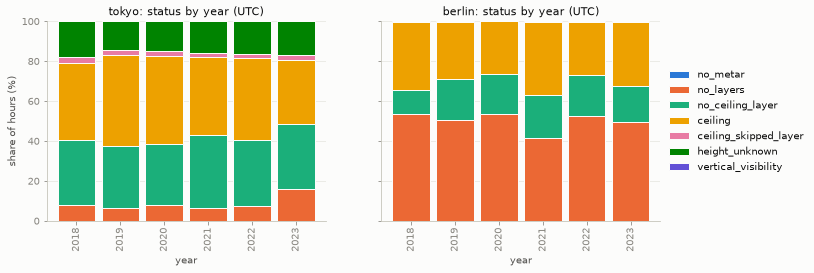

status       no_metar  no_layers  no_ceiling_layer  ceiling  \
city   year                                                   
berlin 2018      0.02      53.46             12.13    34.05   
       2019      0.00      50.73             20.11    29.00   
       2020      0.02      53.44             19.85    26.57   
       2021      0.02      41.26             21.53    37.02   
       2022      0.01      52.69             20.25    26.85   
       2023      0.00      49.37             18.18    32.20   
tokyo  2018      0.01       8.14             32.10    38.93   
       2019      0.00       6.35             31.14    45.80   
       2020      0.01       7.80             30.60    44.29   
       2021      0.01       6.18             36.60    39.08   
       2022      0.00       7.61             32.79    40.99   
       2023      0.03      15.73             32.85    32.08   

status       ceiling_skipped_layer  height_unknown  vertical_visibility  
city   year                                                              
berlin 2018                   0.00            0.00                 0.33  
       2019                   0.00            0.00                 0.16  
       2020                   0.00            0.00                 0.11  
       2021                   0.00            0.00                 0.17  
       2022                   0.00            0.02                 0.17  
       2023                   0.01            0.07                 0.16  
tokyo  2018                   2.67           18.15                 0.00  
       2019                   2.35           14.36                 0.00  
       2020                   2.53           14.77                 0.01  
       2021                   2.09           16.05                 0.00  
       2022                   2.15           16.46                 0.00  
       2023                   2.57           16.74                 0.00

In [13]:
plot_status_share(train, "year", "status by year (UTC)")

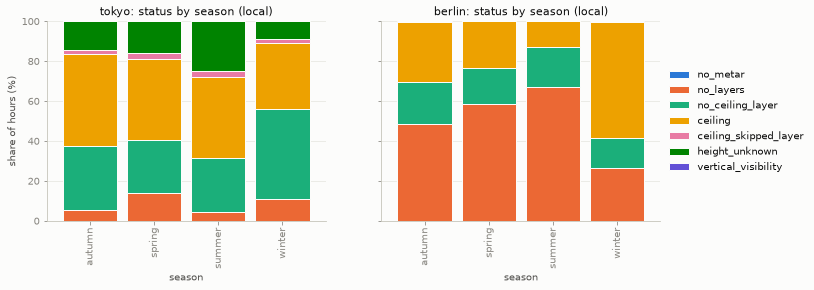

status         no_metar  no_layers  no_ceiling_layer  ceiling  \
city   season                                                   
berlin winter      0.00      26.24             15.32    58.06   
       spring      0.03      58.71             17.68    23.49   
       summer      0.00      66.83             20.27    12.82   
       autumn      0.02      48.36             21.41    29.95   
tokyo  winter      0.00      10.97             45.28    33.06   
       spring      0.02      14.01             26.25    41.03   
       summer      0.02       4.17             27.23    40.81   
       autumn      0.01       5.40             32.20    45.80   

status         ceiling_skipped_layer  height_unknown  vertical_visibility  
city   season                                                              
berlin winter                   0.00            0.01                 0.38  
       spring                   0.00            0.01                 0.08  
       summer                   0.01            0.05                 0.03  
       autumn                   0.00            0.00                 0.26  
tokyo  winter                   1.83            8.87                 0.00  
       spring                   2.60           16.09                 0.01  
       summer                   2.78           24.98                 0.00  
       autumn                   2.35           14.23                 0.00

In [14]:
plot_status_share(train, "season", "status by season (local)").reindex(SEASON_ORDER, level=1)

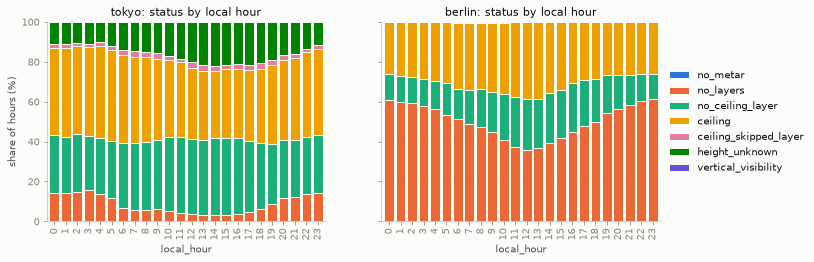

status             no_metar  no_layers  no_ceiling_layer  ceiling  \
city   local_hour                                                   
berlin 0               0.00      60.66             13.14    26.11   
       1               0.00      60.06             13.01    26.79   
       2               0.05      59.11             13.10    27.43   
       3               0.05      57.87             13.56    28.25   
       4               0.00      56.37             13.78    29.58   
       5               0.00      53.17             15.93    30.63   
       6               0.00      51.12             15.43    33.04   
       7               0.00      48.79             16.98    33.82   
       8               0.05      47.06             19.21    33.23   
       9               0.00      44.87             20.13    34.55   
       10              0.00      40.76             23.09    35.74   
       11              0.00      37.15             25.10    37.52   
       12              0.00      36.01             25.33    38.52   
       13              0.00      36.97             24.60    38.29   
       14              0.00      39.39             24.78    35.74   
       15              0.05      41.85             24.01    34.05   
       16              0.05      44.59             24.83    30.49   
       17              0.00      47.74             23.14    28.94   
       18              0.00      49.98             21.31    28.66   
       19              0.05      54.04             19.31    26.52   
       20              0.00      56.23             17.25    26.47   
       21              0.05      58.10             15.43    26.38   
       22              0.00      60.47             13.42    26.06   
       23              0.00      61.48             12.41    25.92   
tokyo  0               0.05      14.19             29.12    43.63   
       1               0.00      14.06             28.39    44.36   
       2               0.00      14.88             28.89    44.23   
       3               0.00      15.65             27.34    44.27   
       4               0.00      13.65             27.98    46.19   
       5               0.00      11.87             28.66    45.28   
       6               0.00       6.66             32.63    44.18   
       7               0.09       5.75             33.41    43.27   
       8               0.05       5.43             34.46    42.36   
       9               0.05       6.07             34.92    40.39   
       10              0.00       5.34             36.97    38.80   
       11              0.00       4.34             37.93    37.43   
       12              0.00       3.79             37.61    35.33   
       13              0.00       3.19             37.65    34.32   
       14              0.00       3.24             38.57    33.32   
       15              0.00       3.29             38.29    34.64   
       16              0.05       3.88             37.88    34.41   
       17              0.00       4.52             35.55    35.60   
       18              0.00       6.25             33.23    36.70   
       19              0.00       8.95             29.85    39.57   
       20              0.00      11.82             29.16    39.71   
       21              0.00      12.14             28.66    41.12   
       22              0.00      13.83             28.34    42.49   
       23              0.00      14.42             28.80    43.09   

status             ceiling_skipped_layer  height_unknown  vertical_visibility  
city   local_hour                                                              
berlin 0                            0.00            0.00                 0.09  
       1                            0.00            0.00                 0.14  
       2                            0.00            0.05                 0.27  
       3                            0.00            0.05                 0.23  
       4                            0.00            0.00             

In [15]:
plot_status_share(train, "local_hour", "status by local hour")

## 3. 高さのない BKN・OVC の層（学習期間、D2）

`ceiling_skipped_layer` の行について、高さのない層が `ceiling_m` を決めた層より **下（前）** にあるか **上（後）** にあるか。

- `above`：高さのない層のほうが上。最も低い BKN・OVC の高さは分かっているので、`ceiling_m` は変わらない。
- `below`：高さのない層のほうが下。実際のシーリングは `ceiling_m` より低い可能性がある。

In [16]:
pd.crosstab(train["city"], train["skipped"].fillna("(not skipped)"))

skipped,(not skipped),above
city,,
berlin,52583,1
tokyo,51326,1258


In [17]:
group = train["status"].where(train["skipped"].isna(), train["status"] + ":" + train["skipped"])
with_height = train[train["has_ceiling"]]
with_height.groupby(["city", group[train["has_ceiling"]]])["ceiling_m"].describe(
    percentiles=[0.1, 0.5, 0.9]
)

count    mean     std     min     10%  \
city   status                                                                 
berlin ceiling                     16273.00  765.65  781.92   30.48  152.40   
       ceiling_skipped_layer:above     1.00 1219.20     NaN 1219.20 1219.20   
tokyo  ceiling                     21136.00 1624.15 1395.39   60.96  304.80   
       ceiling_skipped_layer:above  1258.00 2582.78 1722.55  152.40  752.86   

                                       50%     90%     max  
city   status                                               
berlin ceiling                      640.08 1371.60 9144.00  
       ceiling_skipped_layer:above 1219.20 1219.20 1219.20  
tokyo  ceiling                     1219.20 3962.40 7010.40  
       ceiling_skipped_layer:above 1828.80 5181.60 6705.60

`height_unknown`（BKN・OVC があるのに高さがない）の行で、ほかの層（FEW・SCT）に高さがあるか。最も低い層の高さの分布。

In [18]:
unknown = train[train["status"] == eda.HEIGHT_UNKNOWN]
lowest_layer_m = unknown[[f"sky_height_{layer}_m" for layer in metar.LAYERS]].min(axis=1)
display(
    pd.DataFrame(
        {
            "rows": unknown.groupby("city").size(),
            "with_lower_layer_height": lowest_layer_m.notna().groupby(unknown["city"]).sum(),
        }
    )
)
lowest_layer_m.groupby(unknown["city"]).describe(percentiles=[0.1, 0.5, 0.9])

,rows,with_lower_layer_height
city,,
berlin,8,7
tokyo,8459,8459


,count,mean,std,min,10%,50%,90%,max
city,,,,,,,,
berlin,7.00,426.72,215.53,182.88,201.17,426.72,688.85,762.00
tokyo,8459.00,740.80,260.89,0.00,457.20,762.00,914.40,1828.80


## 4. `ceiling_m` の分布（学習期間、D1）

`ceiling_m` がある行だけ。上限で打ち切る場合の上限の候補を見るため、分位点と、ある高さ以上の割合を出す。

In [19]:
ceilings = train[train["has_ceiling"]]
ceilings.groupby("city")["ceiling_m"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max
city,,,,,,,,,,,,,
berlin,16274.00,765.68,781.90,30.48,30.48,91.44,274.32,640.08,1066.80,1371.60,1463.04,3352.80,9144.00
tokyo,22394.00,1678.00,1432.83,60.96,152.40,213.36,609.60,1219.20,2133.60,4267.20,4876.80,5791.20,7010.40


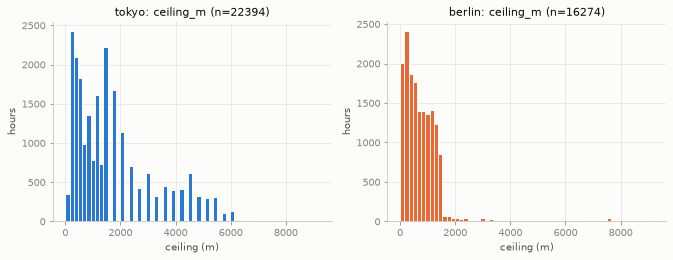

In [20]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(11, 3.6), sharey=False, squeeze=False)
for ax, city in zip(axes[0], CITIES, strict=True):
    values = ceilings.loc[ceilings["city"] == city, "ceiling_m"]
    ax.hist(values, bins=60, range=(0, 9200), color=CITY_COLORS[city], edgecolor=SURFACE)
    ax.set_title(f"{city}: ceiling_m (n={len(values)})")
    ax.set_xlabel("ceiling (m)")
    ax.set_ylabel("hours")
plt.show()

上限の候補（m）ごとの、「`ceiling_m` がその高さ以下」の割合（%。`ceiling_m` がある行に対して）。

In [21]:
THRESHOLDS_M = [300, 600, 1000, 1500, 2000, 3000, 5000, 7000]
below = {
    f"<={limit}": (ceilings["ceiling_m"] <= limit).groupby(ceilings["city"]).mean() * 100
    for limit in THRESHOLDS_M
}
pd.DataFrame(below)

,<=300,<=600,<=1000,<=1500,<=2000,<=3000,<=5000,<=7000
city,,,,,,,,
berlin,25.12,47.59,69.86,96.35,97.57,98.68,99.34,99.40
tokyo,8.88,23.83,40.46,54.40,71.71,81.88,95.98,99.98


よく出る値（METAR の高さは 100 フィート刻みで、高いところでは刻みが粗い）。都市ごとの上位 10。

In [22]:
top_values = (
    ceilings.groupby("city")["ceiling_m"]
    .value_counts()
    .groupby(level="city")
    .head(10)
    .rename("hours")
    .reset_index()
)
top_values["ceiling_ft"] = (top_values["ceiling_m"] / metar.METERS_PER_FOOT).round()
top_values.set_index(["city", "ceiling_m"])

hours  ceiling_ft
city   ceiling_m                   
berlin 213.36       604      700.00
       182.88       588      600.00
       152.40       551      500.00
       121.92       530      400.00
       243.84       506      800.00
       487.68       477     1600.00
       365.76       452     1200.00
       91.44        413      300.00
       335.28       403     1100.00
       518.16       400     1700.00
tokyo  1524.00     2203     5000.00
       1828.80     1673     6000.00
       1219.20     1553     4000.00
       609.60      1362     2000.00
       914.40      1277     3000.00
       2133.60     1146     7000.00
       762.00       902     2500.00
       304.80       779     1000.00
       1066.80      743     3500.00
       1371.60      709     4500.00

## 5. 季節差・都市差・時刻（学習期間）

「シーリングがある割合」と、ある場合の中央値。

**5〜7 節は、シーリングがあるかないかが分かる行だけ** を使う（`ceiling`・`ceiling_skipped_layer`・`no_ceiling_layer`・`no_layers`）。
`height_unknown`（BKN・OVC はあるが高さが分からない）を「ない」側に数えると、東京で「ある割合」が実際より低く出るため。
`vertical_visibility`・`no_metar` も除く。

In [23]:
KNOWN_STATUSES = [eda.CEILING, eda.CEILING_SKIPPED_LAYER, eda.NO_CEILING_LAYER, eda.NO_LAYERS]
usable = train[train["status"].isin(KNOWN_STATUSES)]
pd.DataFrame({"train": train.groupby("city").size(), "usable": usable.groupby("city").size()})

,train,usable
city,,
berlin,52584,52472
tokyo,52584,44118


hours        has_ceiling_pct       median_m        
city   berlin  tokyo          berlin tokyo   berlin   tokyo
season                                                     
winter  12934  11832           58.28 38.28   548.64 1524.00
spring  13227  11113           23.52 52.01   792.48 1219.20
summer  13238   9935           12.83 58.13   914.40  914.40
autumn  13073  11238           30.03 56.15   579.12 1219.20

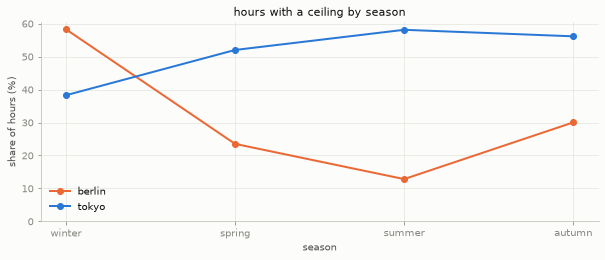

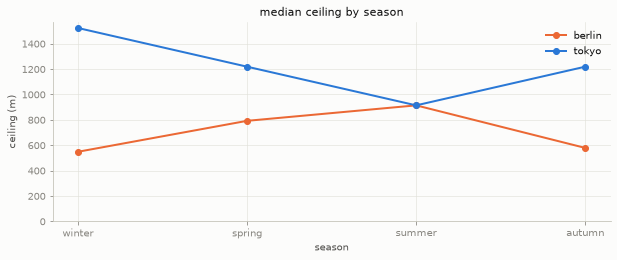

city,berlin,tokyo
season,,
winter,548.64,1524.00
spring,792.48,1219.20
summer,914.40,914.40
autumn,579.12,1219.20


In [24]:
def ceiling_summary(table: pd.DataFrame, by: str) -> pd.DataFrame:
    """by ごと・都市ごとの、行数、ceiling_m がある割合（%）、中央値（m）。"""
    grouped = table.groupby([by, "city"])
    summary = pd.DataFrame(
        {
            "hours": grouped.size(),
            "has_ceiling_pct": grouped["has_ceiling"].mean() * 100,
            "median_m": grouped["ceiling_m"].median(),
        }
    )
    return summary.unstack("city")


by_season = ceiling_summary(usable, "season").reindex(SEASON_ORDER).dropna(how="all")
display(by_season)
plot_by_city(by_season["has_ceiling_pct"], "hours with a ceiling by season", "share of hours (%)")
plot_by_city(by_season["median_m"], "median ceiling by season", "ceiling (m)")

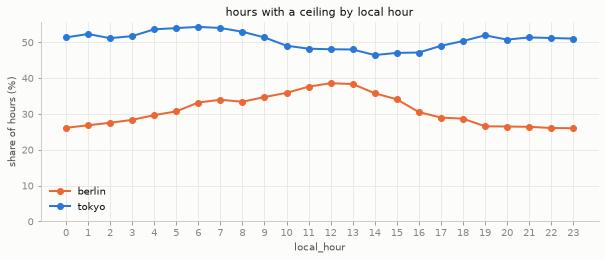

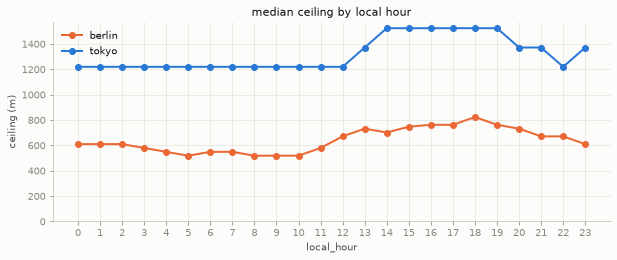

city,berlin,tokyo
local_hour,,
0,609.60,1219.20
1,609.60,1219.20
2,609.60,1219.20
3,579.12,1219.20
4,548.64,1219.20
5,518.16,1219.20
6,548.64,1219.20
7,548.64,1219.20
8,518.16,1219.20


In [25]:
by_hour = ceiling_summary(usable, "local_hour")
plot_by_city(by_hour["has_ceiling_pct"], "hours with a ceiling by local hour", "share of hours (%)")
plot_by_city(by_hour["median_m"], "median ceiling by local hour", "ceiling (m)")

## 6. 露点差との関係（学習期間）

ベースラインは概算式 `125 × (気温 − 露点)` [m]（spec 9）。露点差の 1 ℃ごとの区間で、`ceiling_m` の中央値と概算式を比べる。
気温・露点は、Open-Meteo（過去データ。推論でも使える）と METAR（観測）の両方で見る。
ここでは誤差（MAE）は出さない（#10）。

概算式は「最も低い雲の底」の式なので、参考として、量を問わない最も低い層の高さ（`lowest_layer_m`）の中央値も並べる。

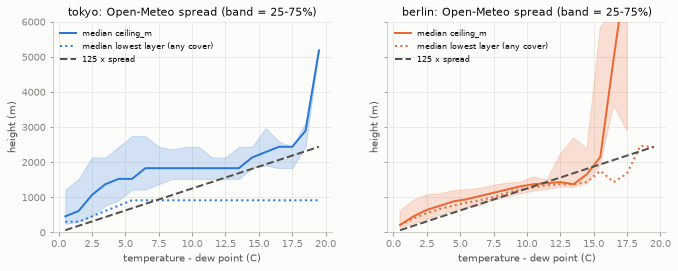

hours  has_ceiling_pct  ceiling_q25_m  ceiling_median_m  \
city   spread_c                                                            
berlin [0, 1)     5449            62.64         121.92            213.36   
       [1, 2)     9371            49.66         243.84            457.20   
       [2, 3)     6330            40.90         365.76            640.08   
       [3, 4)     5428            33.33         487.68            762.00   
       [4, 5)     4475            26.37         609.60            883.92   
       [5, 6)     3691            22.22         701.04            944.88   
       [6, 7)     3065            18.01         762.00           1036.32   
       [7, 8)     2608            17.45         914.40           1127.76   
       [8, 9)     2129            12.92        1005.84           1219.20   
       [9, 10)    1953            10.55        1097.28           1310.64   
       [10, 11)   1626             8.55        1173.48           1371.60   
       [11, 12)   1324             6.72        1219.20           1402.08   
       [12, 13)   1249             4.08        1295.40           1432.56   
       [13, 14)    964             1.66        1280.16           1371.60   
       [14, 15)    818             0.98        1402.08           1661.16   
       [15, 16)    597             1.01        1905.00           2148.84   
       [16, 17)    426             0.47        3619.50           4953.00   
       [17, 18)    351             1.42        2895.60           7620.00   
       [18, 19)    229             0.00            NaN               NaN   
       [19, 20)    151             0.66        7620.00           7620.00   
tokyo  [0, 1)     2040            60.88         243.84            457.20   
       [1, 2)     7279            69.94         304.80            609.60   
       [2, 3)     8378            66.16         457.20           1066.80   
       [3, 4)     6079            59.89         762.00           1371.60   
       [4, 5)     4357            50.75         914.40           1524.00   
       [5, 6)     3418            41.60        1219.20           1524.00   
       [6, 7)     2919            35.70        1219.20           1828.80   
       [7, 8)     2432            30.96        1371.60           1828.80   
       [8, 9)     1874            24.65        1524.00           1828.80   
       [9, 10)    1511            21.64        1524.00           1828.80   
       [10, 11)   1135            23.17        1524.00           1828.80   
       [11, 12)    800            17.25        1524.00           1828.80   
       [12, 13)    607            17.79        1524.00           1828.80   
       [13, 14)    483            16.77        1524.00           1828.80   
       [14, 15)    321            11.84        1828.80           2133.60   
       [15, 16)    215             6.51        1905.00           2286.00   
       [16, 17)    139             5.04        1828.80           2438.40   
       [17, 18)     63             7.94        1828.80           2438.40   
       [18, 19)     36            11.11        2438.40           2895.60   
       [19, 20)     15             6.67        5181.60           5181.60   

                 ceiling_q75_m  lowest_layer_median_m  rule_of_thumb_m  
city   spread_c                                                         
berlin [0, 1)           609.60                 213.36            62.50  
       [1, 2)           914.40                 396.24           187.50  
       [2, 3)          1066.80                 548.64           312.50  
       [3, 4)          1097.28                 670.56           437.50  
       [4, 5)          1188.72                 762.00           562.50  
       [5, 6)          1219.20                 853.44           687.50  
       [6, 7)          1257.30                 914.40           812.50  
       [7, 8)          1341.12                1005.84           937.50  
       [8, 9)          1402.08                1127.76          1062.50  
       [9, 10)       

In [26]:
SPREAD_BINS = list(range(0, 21))
related = usable.assign(
    lowest_layer_m=usable[[f"sky_height_{layer}_m" for layer in metar.LAYERS]].min(axis=1)
)


def by_spread(table: pd.DataFrame, column: str) -> pd.DataFrame:
    """露点差の区間ごと・都市ごとの集計。区間は [n, n+1) ℃。"""
    bins = pd.cut(table[column], SPREAD_BINS, right=False)
    grouped = table.groupby(["city", bins], observed=True)
    summary = pd.DataFrame(
        {
            "hours": grouped.size(),
            "has_ceiling_pct": grouped["has_ceiling"].mean() * 100,
            "ceiling_q25_m": grouped["ceiling_m"].quantile(0.25),
            "ceiling_median_m": grouped["ceiling_m"].median(),
            "ceiling_q75_m": grouped["ceiling_m"].quantile(0.75),
            "lowest_layer_median_m": grouped["lowest_layer_m"].median(),
        }
    )
    lower_edge = pd.Series([interval.left for interval in summary.index.get_level_values(1)])
    summary["rule_of_thumb_m"] = eda.rule_of_thumb_m(lower_edge + 0.5).to_numpy()
    return summary


def plot_spread(summary: pd.DataFrame, title: str) -> None:
    fig, axes = plt.subplots(1, len(CITIES), figsize=(11, 3.8), sharey=True, squeeze=False)
    for ax, city in zip(axes[0], CITIES, strict=True):
        if city not in summary.index.get_level_values("city"):
            continue
        part = summary.loc[city]
        x = [interval.left + 0.5 for interval in part.index]
        ax.fill_between(
            x, part["ceiling_q25_m"], part["ceiling_q75_m"], color=CITY_COLORS[city], alpha=0.2
        )
        ax.plot(x, part["ceiling_median_m"], color=CITY_COLORS[city], label="median ceiling_m")
        ax.plot(
            x,
            part["lowest_layer_median_m"],
            color=CITY_COLORS[city],
            linestyle=":",
            label="median lowest layer (any cover)",
        )
        ax.plot(x, part["rule_of_thumb_m"], color="#52514e", linestyle="--", label="125 x spread")
        ax.set_title(f"{city}: {title}")
        ax.set_xlabel("temperature - dew point (C)")
        ax.set_ylabel("height (m)")
        ax.set_ylim(0, 6000)
        ax.legend(fontsize=8)
    plt.show()


spread_archive = by_spread(related, "spread_c")
plot_spread(spread_archive, "Open-Meteo spread (band = 25-75%)")
spread_archive

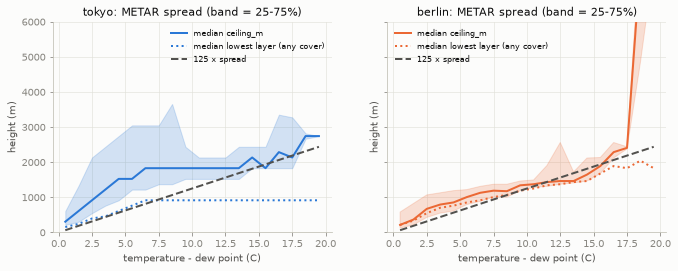

hours  has_ceiling_pct  ceiling_q25_m  \
city   metar_spread_c                                          
berlin [0, 1)           7390            59.28         121.92   
       [1, 2)           6261            49.91         213.36   
       [2, 3)           8705            43.00         426.72   
       [3, 4)           4195            34.59         548.64   
       [4, 5)           3654            27.04         609.60   
       [5, 6)           4285            24.08         792.48   
       [6, 7)           2319            18.80         883.92   
       [7, 8)           2523            16.45        1005.84   
       [8, 9)           1675            12.06        1005.84   
       [9, 10)          1850            10.65        1188.72   
       [10, 11)         1522             8.41        1280.16   
       [11, 12)         1315             6.31        1310.64   
       [12, 13)         1045             3.16        1371.60   
       [13, 14)         1115             2.33        1409.70   
       [14, 15)         1117             1.25        1463.04   
       [15, 16)          823             0.61        1676.40   
       [16, 17)          545             0.55        2118.36   
       [17, 18)          550             0.36        2377.44   
       [18, 19)          448             0.67        4831.08   
       [19, 20)          346             0.29        7620.00   
tokyo  [0, 1)           3188            92.00         213.36   
       [1, 2)           4746            83.57         304.80   
       [2, 3)           5140            71.48         548.64   
       [3, 4)           3689            60.69         762.00   
       [4, 5)           3812            54.67         914.40   
       [5, 6)           4958            48.77        1219.20   
       [6, 7)           2840            39.79        1219.20   
       [7, 8)           3195            37.06        1371.60   
       [8, 9)           1937            29.99        1371.60   
       [9, 10)          1981            28.52        1524.00   
       [10, 11)         2000            25.60        1524.00   
       [11, 12)         1511            23.03        1524.00   
       [12, 13)         1120            20.71        1524.00   
       [13, 14)         1299            17.86        1524.00   
       [14, 15)          876            15.07        1828.80   
       [15, 16)          618            13.92        1828.80   
       [16, 17)          362             9.94        1828.80   
       [17, 18)          346             7.51        1828.80   
       [18, 19)          189             2.12        2667.00   
       [19, 20)          109             0.92        2743.20   

                       ceiling_median_m  ceiling_q75_m  lowest_layer_median_m  \
city   metar_spread_c                                                           
berlin [0, 1)                    213.36         579.12                 213.36   
       [1, 2)                    365.76         822.96                 335.28   
       [2, 3)                    670.56        1066.80                 548.64   
       [3, 4)                    792.48        1127.76                 701.04   
       [4, 5)                    853.44        1188.72                 762.00   
       [5, 6)                   1005.84        1219.20                 853.44   
       [6, 7)                   1127.76        1310.64                 914.40   
       [7, 8)                   1188.72        1371.60                1005.84   
       [8, 9)                   1173.48        1371.60                1066.80   
       [9, 10)                  1341.12        1463.04                1188.72   
       [10, 11)                 1371.60        1493.52                1249.68   
       [11, 12)                 1432.56        1905.00                1341.12   
       [12, 13)                 1463.04        2560.32                1371.60   
       [13, 14)                 1463.04        1722.12                1432.56   
       [14, 15)                 1645.9

In [27]:
spread_metar = by_spread(related, "metar_spread_c")
plot_spread(spread_metar, "METAR spread (band = 25-75%)")
spread_metar

散布図（都市ごとに最大 4,000 点を、シードを固定して抜き出す）。

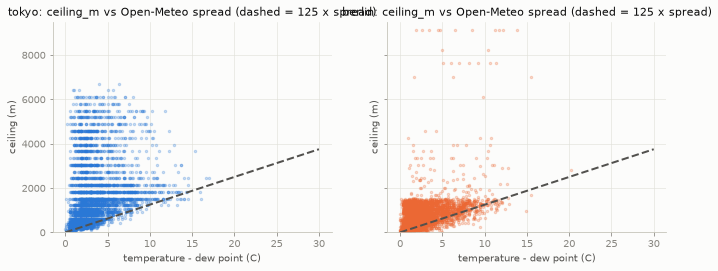

In [28]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(11, 3.8), sharey=True, squeeze=False)
for ax, city in zip(axes[0], CITIES, strict=True):
    points = related[(related["city"] == city) & related["has_ceiling"]]
    points = points.sample(n=min(len(points), 4000), random_state=SEED)
    ax.scatter(points["spread_c"], points["ceiling_m"], s=6, alpha=0.25, color=CITY_COLORS[city])
    line_x = pd.Series([0.0, 30.0])
    ax.plot(line_x, eda.rule_of_thumb_m(line_x), color="#52514e", linestyle="--")
    ax.set_title(f"{city}: ceiling_m vs Open-Meteo spread (dashed = 125 x spread)")
    ax.set_xlabel("temperature - dew point (C)")
    ax.set_ylabel("ceiling (m)")
    ax.set_ylim(0, 9500)
plt.show()

順位相関（Spearman）。`ceiling_m` がある行だけ。

In [29]:
FEATURES = [
    "spread_c",
    "metar_spread_c",
    "temperature_c",
    "dew_point_c",
    "relative_humidity",
    "pressure_msl_hpa",
    "precipitation_mm",
    "cloud_cover",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "wind_speed_ms",
    "visibility_m",
]


def spearman(x: pd.Series, y: pd.Series) -> float:
    """順位相関。両方がそろっている行の順位（同じ値は平均の順位）どうしの相関。"""
    both = pd.concat([x.astype("float64"), y.astype("float64")], axis=1).dropna()
    return float(both.iloc[:, 0].rank().corr(both.iloc[:, 1].rank()))


def rank_correlation(table: pd.DataFrame, target: str) -> pd.DataFrame:
    result = {
        city: {name: spearman(part[name], part[target]) for name in FEATURES}
        for city, part in table.groupby("city")
    }
    return pd.DataFrame(result)


rank_correlation(related[related["has_ceiling"]], "ceiling_m")

,berlin,tokyo
spread_c,0.52,0.39
metar_spread_c,0.60,0.55
temperature_c,0.26,-0.01
dew_point_c,0.09,-0.11
relative_humidity,-0.52,-0.38
pressure_msl_hpa,-0.05,0.13
precipitation_mm,-0.08,-0.37
cloud_cover,-0.27,-0.23
cloud_cover_low,-0.37,-0.57
cloud_cover_mid,-0.01,-0.04


## 7. ほかの特徴量の候補（学習期間）

「シーリングがあるか」（`has_ceiling`）との順位相関と、Open-Meteo の低い雲の量・湿度の区間ごとの割合。
`visibility_m` は METAR の値（推論では使えない）なので、参考。

In [30]:
rank_correlation(related, "has_ceiling")

,berlin,tokyo
spread_c,-0.40,-0.34
metar_spread_c,-0.41,-0.48
temperature_c,-0.35,0.11
dew_point_c,-0.21,0.21
relative_humidity,0.40,0.34
pressure_msl_hpa,-0.10,-0.10
precipitation_mm,0.34,0.46
cloud_cover,0.42,0.72
cloud_cover_low,0.66,0.57
cloud_cover_mid,0.22,0.65


hours        has_ceiling_pct       median_m        
city            berlin  tokyo          berlin tokyo   berlin   tokyo
cloud_cover_low                                                     
(-0.001, 10.0]   28289  25913            6.00 29.21  1036.32 2133.60
(10.0, 25.0]      5308   4677           24.96 62.37  1005.84 1524.00
(25.0, 50.0]      4384   3607           43.43 74.94   914.40 1219.20
(50.0, 75.0]      2606   1714           56.95 82.73   853.44 1219.20
(75.0, 90.0]      1767   1105           67.40 88.05   792.48  975.36
(90.0, 100.0]    10118   7102           85.71 95.96   457.20  609.60

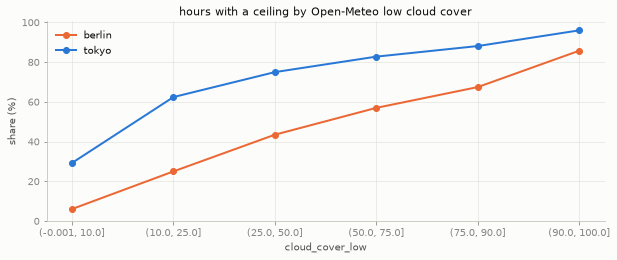

city,berlin,tokyo
cloud_cover_low,,
"(-0.001, 10.0]",6.00,29.21
"(10.0, 25.0]",24.96,62.37
"(25.0, 50.0]",43.43,74.94
"(50.0, 75.0]",56.95,82.73
"(75.0, 90.0]",67.40,88.05
"(90.0, 100.0]",85.71,95.96


In [31]:
def by_bins(table: pd.DataFrame, column: str, edges: list[float]) -> pd.DataFrame:
    bins = pd.cut(table[column], edges, include_lowest=True)
    grouped = table.groupby([bins, "city"], observed=True)
    summary = pd.DataFrame(
        {
            "hours": grouped.size(),
            "has_ceiling_pct": grouped["has_ceiling"].mean() * 100,
            "median_m": grouped["ceiling_m"].median(),
        }
    )
    return summary.unstack("city")


low_cloud = by_bins(related, "cloud_cover_low", [0, 10, 25, 50, 75, 90, 100])
display(low_cloud)
plot_by_city(
    low_cloud["has_ceiling_pct"], "hours with a ceiling by Open-Meteo low cloud cover", "share (%)"
)

hours        has_ceiling_pct       median_m        
city              berlin  tokyo          berlin tokyo   berlin   tokyo
relative_humidity                                                     
(-0.001, 40.0]      2885   1224            1.49 11.85  2286.00 2133.60
(40.0, 50.0]        4455   2614            5.16 19.93  1402.08 1828.80
(50.0, 60.0]        5760   4559           12.66 24.68  1219.20 1828.80
(60.0, 70.0]        7458   6298           19.80 36.44  1005.84 1524.00
(70.0, 80.0]        9539   9167           29.07 52.26   822.96 1524.00
(80.0, 90.0]       11846  14282           42.41 66.76   579.12 1066.80
(90.0, 100.0]      10529   5974           56.97 66.67   304.80  548.64

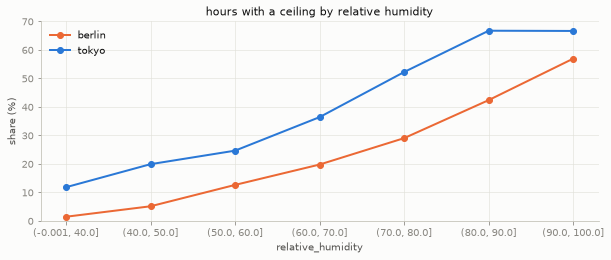

city,berlin,tokyo
relative_humidity,,
"(-0.001, 40.0]",1.49,11.85
"(40.0, 50.0]",5.16,19.93
"(50.0, 60.0]",12.66,24.68
"(60.0, 70.0]",19.80,36.44
"(70.0, 80.0]",29.07,52.26
"(80.0, 90.0]",42.41,66.76
"(90.0, 100.0]",56.97,66.67


In [32]:
humidity = by_bins(related, "relative_humidity", [0, 40, 50, 60, 70, 80, 90, 100])
display(humidity)
plot_by_city(humidity["has_ceiling_pct"], "hours with a ceiling by relative humidity", "share (%)")

## 8. 年ごとの件数（全期間、D5）

学習・検証・テストに当たる年の、区分ごとの件数。中身（分布）は見ず、件数だけを見る。

In [33]:
by_year = status_counts(obs, ["city", "split", "year"])
by_year["hours"] = by_year.sum(axis=1)
by_year["with_ceiling_m"] = by_year[eda.CEILING] + by_year[eda.CEILING_SKIPPED_LAYER]
by_year

status                  no_metar  no_layers  no_ceiling_layer  ceiling  \
city   split      year                                                   
berlin test       2025         0       4535              1608     2517   
       train      2018         2       4683              1063     2983   
                  2019         0       4444              1762     2540   
                  2020         2       4694              1744     2334   
                  2021         2       3614              1886     3243   
                  2022         1       4616              1774     2352   
                  2023         0       4325              1593     2821   
       validation 2024         0       4403              1504     2824   
tokyo  test       2025         0       1315              2595     3235   
       train      2018         1        713              2812     3410   
                  2019         0        556              2728     4012   
                  2020         1        685              2688     3890   
                  2021         1        541              3206     3423   
                  2022         0        667              2872     3591   
                  2023         3       1378              2878     2810   
       validation 2024         0       1230              2449     3387   

status                  ceiling_skipped_layer  height_unknown  \
city   split      year                                          
berlin test       2025                     13               6   
       train      2018                      0               0   
                  2019                      0               0   
                  2020                      0               0   
                  2021                      0               0   
                  2022                      0               2   
                  2023                      1               6   
       validation 2024                      1               2   
tokyo  test       2025                    180            1435   
       train      2018                    234            1590   
                  2019                    206            1258   
                  2020                    222            1297   
                  2021                    183            1406   
                  2022                    188            1442   
                  2023                    225            1466   
       validation 2024                    215            1503   

status                  vertical_visibility  hours  with_ceiling_m  
city   split      year                                              
berlin test       2025                   81   8760            2530  
       train      2018                   29   8760            2983  
                  2019                   14   8760            2540  
                  2020                   10   8784            2334  
                  2021                   15   8760            3243  
                  2022                   15   8760            2352  
                  2023                   14   8760            2822  
       validation 2024                   50   8784            2825  
tokyo  test       2025                    0   8760            3415  
       train      2018                    0   8760            3644  
                  2019                    0   8760            4218  
                  2020                    1   8784            4112  
                  2021                    0   8760            3606  
                  2022                    0   8760            3779  
                  2023                    0   8760            3035  
       validation 2024                    0   8784            3602

In [34]:
by_split = status_counts(obs, ["city", "split"])
display(by_split)
percent(by_split)

status             no_metar  no_layers  no_ceiling_layer  ceiling  \
city   split                                                        
berlin test               0       4535              1608     2517   
       train              7      26376              9822    16273   
       validation         0       4403              1504     2824   
tokyo  test               0       1315              2595     3235   
       train              6       4540             17184    21136   
       validation         0       1230              2449     3387   

status             ceiling_skipped_layer  height_unknown  vertical_visibility  
city   split                                                                   
berlin test                           13               6                   81  
       train                           1               8                   97  
       validation                      1               2                   50  
tokyo  test                          180            1435                    0  
       train                        1258            8459                    1  
       validation                    215            1503                    0

status             no_metar  no_layers  no_ceiling_layer  ceiling  \
city   split                                                        
berlin test            0.00      51.77             18.36    28.73   
       train           0.01      50.16             18.68    30.95   
       validation      0.00      50.13             17.12    32.15   
tokyo  test            0.00      15.01             29.62    36.93   
       train           0.01       8.63             32.68    40.19   
       validation      0.00      14.00             27.88    38.56   

status             ceiling_skipped_layer  height_unknown  vertical_visibility  
city   split                                                                   
berlin test                         0.15            0.07                 0.92  
       train                        0.00            0.02                 0.18  
       validation                   0.01            0.02                 0.57  
tokyo  test                         2.05           16.38                 0.00  
       train                        2.39           16.09                 0.00  
       validation                   2.45           17.11                 0.00

年ごとの割合（%）。`no_ceiling` は「雲が少ない・ない」（`no_layers` + `no_ceiling_layer`）で、
D1 を「上限で打ち切る」にした場合に、上限の値になる行。

In [35]:
year_pct = percent(status_counts(obs, ["city", "split", "year"]))
pd.DataFrame(
    {
        "no_ceiling": year_pct[eda.NO_LAYERS] + year_pct[eda.NO_CEILING_LAYER],
        "with_ceiling_m": year_pct[eda.CEILING] + year_pct[eda.CEILING_SKIPPED_LAYER],
        "height_unknown": year_pct[eda.HEIGHT_UNKNOWN],
        "vertical_visibility": year_pct[eda.VERTICAL_VISIBILITY],
    }
)

no_ceiling  with_ceiling_m  height_unknown  \
city   split      year                                               
berlin test       2025       70.13           28.88            0.07   
       train      2018       65.59           34.05            0.00   
                  2019       70.84           29.00            0.00   
                  2020       73.29           26.57            0.00   
                  2021       62.79           37.02            0.00   
                  2022       72.95           26.85            0.02   
                  2023       67.56           32.21            0.07   
       validation 2024       67.25           32.16            0.02   
tokyo  test       2025       44.63           38.98           16.38   
       train      2018       40.24           41.60           18.15   
                  2019       37.49           48.15           14.36   
                  2020       38.40           46.81           14.77   
                  2021       42.77           41.16           16.05   
                  2022       40.40           43.14           16.46   
                  2023       48.58           34.65           16.74   
       validation 2024       41.88           41.01           17.11   

                        vertical_visibility  
city   split      year                       
berlin test       2025                 0.92  
       train      2018                 0.33  
                  2019                 0.16  
                  2020                 0.11  
                  2021                 0.17  
                  2022                 0.17  
                  2023                 0.16  
       validation 2024                 0.57  
tokyo  test       2025                 0.00  
       train      2018                 0.00  
                  2019                 0.00  
                  2020                 0.01  
                  2021                 0.00  
                  2022                 0.00  
                  2023                 0.00  
       validation 2024                 0.00

観測のしかたの変化（学習データの期間を決める材料）。電文に `AUTO`（自動観測）が入っている割合と、
`CAVOK` の割合（%。METAR が付いた正時に対して）。

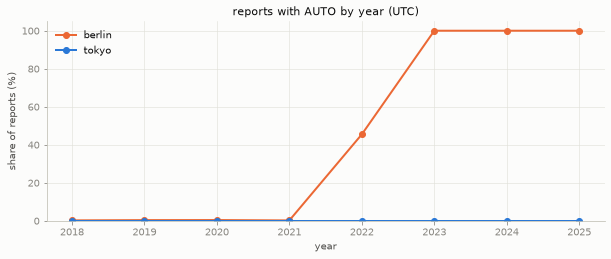

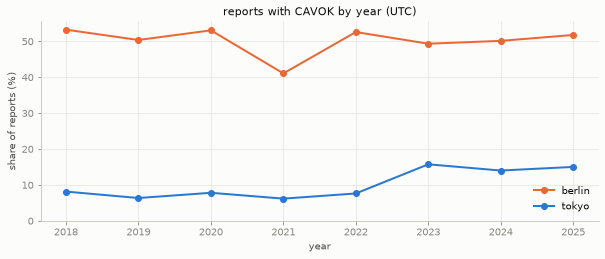

auto_pct       cavok_pct      
city   berlin tokyo    berlin tokyo
year                               
2018     0.23  0.00     53.24  8.14
2019     0.37  0.00     50.37  6.35
2020     0.40  0.00     53.05  7.80
2021     0.21  0.00     41.06  6.18
2022    45.50  0.00     52.59  7.61
2023   100.00  0.00     49.33 15.74
2024   100.00  0.00     50.13 14.00
2025   100.00  0.00     51.77 15.01

In [36]:
reports = obs[obs["metar"].notna()]
flags = pd.DataFrame(
    {
        "city": reports["city"],
        "year": reports["year"],
        "auto_pct": reports["metar"].str.contains(" AUTO ", regex=False),
        "cavok_pct": reports["metar"].str.contains(" CAVOK ", regex=False),
    }
)
regime = (flags.groupby(["year", "city"])[["auto_pct", "cavok_pct"]].mean() * 100).unstack("city")
plot_by_city(regime["auto_pct"], "reports with AUTO by year (UTC)", "share of reports (%)")
plot_by_city(regime["cavok_pct"], "reports with CAVOK by year (UTC)", "share of reports (%)")
regime

## 9. まとめ（`docs/eda.md` に写す数値）

件数は全期間（`all`）と学習期間（`train`）。分位点・相関は学習期間。

In [37]:
def summarize(city: str) -> dict[str, float]:
    everything = obs[obs["city"] == city]
    part = train[train["city"] == city]
    with_ceiling = part[part["has_ceiling"]]
    result: dict[str, float] = {"all: hours": len(everything), "train: hours": len(part)}
    for status in STATUS_ORDER:
        result[f"all: {status}"] = int((everything["status"] == status).sum())
    for status in STATUS_ORDER:
        result[f"train: {status}"] = int((part["status"] == status).sum())
    for status in STATUS_ORDER:
        result[f"train: {status} (%)"] = float((part["status"] == status).mean() * 100)
    for position in (eda.BELOW, eda.ABOVE):
        result[f"all: skipped layer {position}"] = int((everything["skipped"] == position).sum())
    for position in (eda.BELOW, eda.ABOVE):
        result[f"train: skipped layer {position}"] = int((part["skipped"] == position).sum())
    for quantile in (0.5, 0.9, 0.95, 0.99):
        result[f"train: ceiling_m q{int(quantile * 100)}"] = with_ceiling["ceiling_m"].quantile(
            quantile
        )
    result["train: ceiling_m max"] = with_ceiling["ceiling_m"].max()
    for column in ("spread_c", "metar_spread_c"):
        result[f"train: spearman(ceiling_m, {column})"] = spearman(
            with_ceiling["ceiling_m"], with_ceiling[column]
        )
    return result


pd.DataFrame({city: summarize(city) for city in CITIES})

,tokyo,berlin
all: hours,70128.00,70128.00
train: hours,52584.00,52584.00
all: no_metar,6.00,7.00
all: no_layers,7085.00,35314.00
all: no_ceiling_layer,22228.00,12934.00
all: ceiling,27758.00,21614.00
all: ceiling_skipped_layer,1653.00,15.00
all: height_unknown,11397.00,16.00
all: vertical_visibility,1.00,228.00
train: no_metar,6.00,7.00
